#Que.1
The iris.csv dataset contains measurements of iris flowers belonging to three different species:
Each flower is described using four numerical features:
Sepal Length (cm)
Sepal Width (cm)
Petal Length (cm)
Petal Width (cm)
The dataset consists of 150 records & you have to predict the species of iris flowers.
Prepare model by using Logistic Regression, KNN, SVM, Decision Tree, Random Forest, AdaBoost, CatBoost & Calculate Accuracy by confusion matrix, Calculate accuracy score, precision score, recall score, f1 score.
Also Prepare summary of all models & Select best of them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings(action='ignore')


df=pd.read_csv(r"C:\Users\SUMEDH\Desktop\New folder\IIT-08-A-DS\Datasets\iris.csv")
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [2]:
from catboost import CatBoostClassifier

In [3]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [7]:
print(df.isna().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [8]:
unique_species= df['species'].unique()

In [9]:
unique_species

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [10]:
unique_species_numbers = [1,2,3] 
df.replace(unique_species,unique_species_numbers,inplace=True)

In [11]:
df.corr()

,sepal_length,sepal_width,petal_length,petal_width,species
sepal_length,1.000000,-0.109369,0.871754,0.817954,0.782561
sepal_width,-0.109369,1.000000,-0.420516,-0.356544,-0.419446
petal_length,0.871754,-0.420516,1.000000,0.962757,0.949043
petal_width,0.817954,-0.356544,0.962757,1.000000,0.956464
species,0.782561,-0.419446,0.949043,0.956464,1.000000


<Axes: >

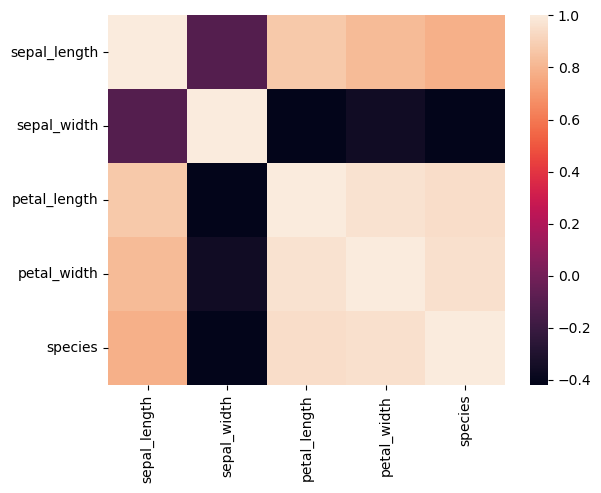

In [12]:
import seaborn as sns
sns.heatmap(df.corr())

In [13]:
df.drop(['sepal_width'],axis=1,inplace=True)

In [14]:
df

,sepal_length,petal_length,petal_width,species
0,5.1,1.4,0.2,1
1,4.9,1.4,0.2,1
2,4.7,1.3,0.2,1
3,4.6,1.5,0.2,1
4,5.0,1.4,0.2,1
...,...,...,...,...
145,6.7,5.2,2.3,3
146,6.3,5.0,1.9,3
147,6.5,5.2,2.0,3
148,6.2,5.4,2.3,3


In [15]:
x=df.drop(['species'],axis=1)
y=df['species']

In [16]:
x.head()

,sepal_length,petal_length,petal_width
0,5.1,1.4,0.2
1,4.9,1.4,0.2
2,4.7,1.3,0.2
3,4.6,1.5,0.2
4,5.0,1.4,0.2


In [17]:
y.head()

0    1
1    1
2    1
3    1
4    1
Name: species, dtype: int64

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
sc1=MinMaxScaler()
x_std1=sc1.fit_transform(x)
x_std1

array([[0.22222222, 0.06779661, 0.04166667],
       [0.16666667, 0.06779661, 0.04166667],
       [0.11111111, 0.05084746, 0.04166667],
       [0.08333333, 0.08474576, 0.04166667],
       [0.19444444, 0.06779661, 0.04166667],
       [0.30555556, 0.11864407, 0.125     ],
       [0.08333333, 0.06779661, 0.08333333],
       [0.19444444, 0.08474576, 0.04166667],
       [0.02777778, 0.06779661, 0.04166667],
       [0.16666667, 0.08474576, 0.        ],
       [0.30555556, 0.08474576, 0.04166667],
       [0.13888889, 0.10169492, 0.04166667],
       [0.13888889, 0.06779661, 0.        ],
       [0.        , 0.01694915, 0.        ],
       [0.41666667, 0.03389831, 0.04166667],
       [0.38888889, 0.08474576, 0.125     ],
       [0.30555556, 0.05084746, 0.125     ],
       [0.22222222, 0.06779661, 0.08333333],
       [0.38888889, 0.11864407, 0.08333333],
       [0.22222222, 0.08474576, 0.08333333],
       [0.30555556, 0.11864407, 0.04166667],
       [0.22222222, 0.08474576, 0.125     ],
       [0.

In [19]:
x2=pd.DataFrame(x_std1)
x2.columns=x.columns

In [20]:
x

,sepal_length,petal_length,petal_width
0,5.1,1.4,0.2
1,4.9,1.4,0.2
2,4.7,1.3,0.2
3,4.6,1.5,0.2
4,5.0,1.4,0.2
...,...,...,...
145,6.7,5.2,2.3
146,6.3,5.0,1.9
147,6.5,5.2,2.0
148,6.2,5.4,2.3


In [21]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=123456)

In [22]:
from sklearn.linear_model import LogisticRegressionCV
model101=LogisticRegressionCV()
model101.fit(x_train,y_train)

LogisticRegressionCV()

In [23]:
from sklearn.neighbors import KNeighborsClassifier
model102=KNeighborsClassifier(n_neighbors=9)


In [24]:
model102.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=9)

In [25]:
from sklearn.svm import SVC
model103= SVC(C=2,kernel='rbf')

In [26]:
model103.fit(x_train,y_train)

SVC(C=2)

In [27]:
from sklearn.tree import DecisionTreeClassifier
model104=DecisionTreeClassifier()
model104.fit(x_train,y_train)

DecisionTreeClassifier()

In [28]:
from sklearn.ensemble import RandomForestClassifier

model105= RandomForestClassifier()

model105.fit(x_train,y_train)

RandomForestClassifier()

In [29]:
from sklearn.ensemble import AdaBoostClassifier
model106 = AdaBoostClassifier()
model106.fit(x_train, y_train)


AdaBoostClassifier()

In [30]:
from catboost import CatBoostClassifier
model107 = CatBoostClassifier(logging_level='Silent')
model107.fit(x_train, y_train)


In [31]:
model101.predict([[5.1,1.4,0.2]])

array([1])

In [32]:
model102.predict([[5.1,1.4,0.2]])

array([1])

In [33]:
model103.predict([[5.1,1.4,0.2]])

array([1])

In [34]:
model104.predict([[5.1,1.4,0.2]])

array([1])

In [35]:
model105.predict([[5.1,1.4,0.2]])

array([1])

In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred101 = model101.predict(x_test)
y_true101 = y_test

accuracy101 = accuracy_score(y_true101, y_pred101)
precision101 = precision_score(y_true101, y_pred101, average='macro')
recall101 = recall_score(y_true101, y_pred101, average='macro')
f1101 = f1_score(y_true101, y_pred101, average='macro')

print(f"accuracy = {accuracy101:.2f}")
print(f"precision = {precision101:.2f}")
print(f"recall = {recall101:.2f}")
print(f"f1 = {f1101:.2f}")

accuracy = 1.00
precision = 1.00
recall = 1.00
f1 = 1.00


In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred102 = model102.predict(x_test)
y_true102 = y_test

accuracy102 = accuracy_score(y_true102, y_pred102)
precision102 = precision_score(y_true102, y_pred102, average='macro')
recall102 = recall_score(y_true102, y_pred102, average='macro')
f1102 = f1_score(y_true102, y_pred102, average='macro')

print(f"accuracy = {accuracy102:.2f}")
print(f"precision = {precision102:.2f}")
print(f"recall = {recall102:.2f}")
print(f"f1 = {f1102:.2f}")

accuracy = 1.00
precision = 1.00
recall = 1.00
f1 = 1.00


In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred103 = model103.predict(x_test)
y_true103= y_test

accuracy103= accuracy_score(y_true103, y_pred103)
precision103 = precision_score(y_true103, y_pred103, average='macro')
recall103 = recall_score(y_true103, y_pred103, average='macro')
f1103 = f1_score(y_true103, y_pred103, average='macro')

print(f"accuracy = {accuracy103:.2f}")
print(f"precision = {precision103:.2f}")
print(f"recall = {recall103:.2f}")
print(f"f1 = {f1103:.2f}")

accuracy = 1.00
precision = 1.00
recall = 1.00
f1 = 1.00


In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred104= model104.predict(x_test)
y_true104 = y_test

accuracy104 = accuracy_score(y_true104, y_pred104)
precision104 = precision_score(y_true104, y_pred104, average='macro')
recall104 = recall_score(y_true104, y_pred104, average='macro')
f1104 = f1_score(y_true104, y_pred104, average='macro')

print(f"accuracy = {accuracy104:.2f}")
print(f"precision = {precision104:.2f}")
print(f"recall = {recall104:.2f}")
print(f"f1 = {f1104:.2f}")

accuracy = 0.97
precision = 0.97
recall = 0.97
f1 = 0.97


In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred105 = model105.predict(x_test)
y_true105 = y_test

accuracy105 = accuracy_score(y_true105, y_pred105)
precision105 = precision_score(y_true105, y_pred105, average='macro')
recall105 = recall_score(y_true105, y_pred105, average='macro')
f1105 = f1_score(y_true105, y_pred105, average='macro')

print(f"accuracy = {accuracy105:.2f}")
print(f"precision = {precision105:.2f}")
print(f"recall = {recall105:.2f}")
print(f"f1 = {f1105:.2f}")

accuracy = 0.97
precision = 0.97
recall = 0.97
f1 = 0.97


In [41]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred106 = model106.predict(x_test)
y_true106 = y_test

accuracy106 = accuracy_score(y_true106, y_pred106)
precision106 = precision_score(y_true106, y_pred106, average='macro')
recall106 = recall_score(y_true106, y_pred106, average='macro')
f1106 = f1_score(y_true106, y_pred106, average='macro')

print(f"accuracy = {accuracy106:.2f}")
print(f"precision = {precision106:.2f}")
print(f"recall = {recall106:.2f}")
print(f"f1 = {f1106:.2f}")

accuracy = 0.97
precision = 0.97
recall = 0.97
f1 = 0.97


In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred107 = model107.predict(x_test)
y_true107 = y_test

accuracy107 = accuracy_score(y_true107, y_pred107)
precision107 = precision_score(y_true107, y_pred107, average='macro')
recall107 = recall_score(y_true107, y_pred107, average='macro')
f1107 = f1_score(y_true107, y_pred107, average='macro')

print(f"accuracy = {accuracy107:.2f}")
print(f"precision = {precision107:.2f}")
print(f"recall = {recall107:.2f}")
print(f"f1 = {f1107:.2f}")

accuracy = 0.97
precision = 0.97
recall = 0.97
f1 = 0.97


#Que.2
The titanic.csv dataset contains information about passengers aboard the RMS Titanic, 
including their demographic details, travel class, and fare information. 
The dataset aims to analyze the factors that influenced passenger survival during the tragic shipwreck.
Each record in the dataset represents one passenger with the following attributes:
PassengerId
Survived (0 = No, 1 = Yes)
Pclass (Passenger class: 1st, 2nd, 3rd)
Name
Sex
Age
SibSp (Number of siblings/spouses aboard)
Parch (Number of parents/children aboard)
Ticket
Fare
Cabin
Embarked (Port of embarkation: C, Q, S)
Build Logistic Regression, KNN, SVM, Decision Tree, Random Forest, AdaBoost, CatBoost models to predict whether a passenger survived or not & 
Calculate Accuracy by confusion matrix, Calculate accuracy score, precision score, recall score, f1 score.
Also Prepare summary of all models & Select best of them

In [43]:
df1=pd.read_csv(r"C:\Users\SUMEDH\Desktop\New folder\IIT-08-A-DS\Datasets\titanic.csv")
df1

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [44]:
df1.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [45]:
df1.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [46]:
df1.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [47]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [48]:
df1['Name'].unique()

array(['Braund, Mr. Owen Harris',
       'Cumings, Mrs. John Bradley (Florence Briggs Thayer)',
       'Heikkinen, Miss. Laina',
       'Futrelle, Mrs. Jacques Heath (Lily May Peel)',
       'Allen, Mr. William Henry', 'Moran, Mr. James',
       'McCarthy, Mr. Timothy J', 'Palsson, Master. Gosta Leonard',
       'Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)',
       'Nasser, Mrs. Nicholas (Adele Achem)',
       'Sandstrom, Miss. Marguerite Rut', 'Bonnell, Miss. Elizabeth',
       'Saundercock, Mr. William Henry', 'Andersson, Mr. Anders Johan',
       'Vestrom, Miss. Hulda Amanda Adolfina',
       'Hewlett, Mrs. (Mary D Kingcome) ', 'Rice, Master. Eugene',
       'Williams, Mr. Charles Eugene',
       'Vander Planke, Mrs. Julius (Emelia Maria Vandemoortele)',
       'Masselmani, Mrs. Fatima', 'Fynney, Mr. Joseph J',
       'Beesley, Mr. Lawrence', 'McGowan, Miss. Anna "Annie"',
       'Sloper, Mr. William Thompson', 'Palsson, Miss. Torborg Danira',
       'Asplund, Mrs. Carl Oscar 

In [49]:
df1['Sex'].unique()

array(['male', 'female'], dtype=object)

In [50]:
df1['Ticket'].unique()

array(['A/5 21171', 'PC 17599', 'STON/O2. 3101282', '113803', '373450',
       '330877', '17463', '349909', '347742', '237736', 'PP 9549',
       '113783', 'A/5. 2151', '347082', '350406', '248706', '382652',
       '244373', '345763', '2649', '239865', '248698', '330923', '113788',
       '347077', '2631', '19950', '330959', '349216', 'PC 17601',
       'PC 17569', '335677', 'C.A. 24579', 'PC 17604', '113789', '2677',
       'A./5. 2152', '345764', '2651', '7546', '11668', '349253',
       'SC/Paris 2123', '330958', 'S.C./A.4. 23567', '370371', '14311',
       '2662', '349237', '3101295', 'A/4. 39886', 'PC 17572', '2926',
       '113509', '19947', 'C.A. 31026', '2697', 'C.A. 34651', 'CA 2144',
       '2669', '113572', '36973', '347088', 'PC 17605', '2661',
       'C.A. 29395', 'S.P. 3464', '3101281', '315151', 'C.A. 33111',
       'S.O.C. 14879', '2680', '1601', '348123', '349208', '374746',
       '248738', '364516', '345767', '345779', '330932', '113059',
       'SO/C 14885', '31012

In [51]:
df1['Cabin'].unique()

array([nan, 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'B28', 'C83', 'F33',
       'F G73', 'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101',
       'F E69', 'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4',
       'A32', 'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35',
       'C87', 'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19',
       'B49', 'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54',
       'B57 B59 B63 B66', 'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40',
       'T', 'C128', 'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44',
       'A34', 'C104', 'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14',
       'B37', 'C30', 'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38',
       'B39', 'B22', 'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68',
       'B41', 'A20', 'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48',
       'E58', 'C126', 'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63',
       'C62 C64',

In [52]:
df1['Embarked'].unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [53]:
from sklearn.preprocessing import LabelEncoder
df1['Name']=LabelEncoder().fit_transform(df1['Name'])

In [54]:
from sklearn.preprocessing import LabelEncoder
df1['Sex']=LabelEncoder().fit_transform(df1['Sex'])

In [55]:
from sklearn.preprocessing import LabelEncoder
df1['Ticket']=LabelEncoder().fit_transform(df1['Ticket'])

In [56]:
from sklearn.preprocessing import LabelEncoder
df1['Cabin']=LabelEncoder().fit_transform(df1['Cabin'])

In [57]:
from sklearn.preprocessing import LabelEncoder
df1['Embarked']=LabelEncoder().fit_transform(df1['Embarked'])

In [58]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    int64  
 4   Sex          891 non-null    int64  
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    int64  
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    int64  
 11  Embarked     891 non-null    int64  
dtypes: float64(2), int64(10)
memory usage: 83.7 KB


In [59]:
print(df1.isna().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin            0
Embarked         0
dtype: int64


In [60]:
df1['Age'].fillna(df1['Age'].mean(), inplace=True)


In [61]:
print(df1.isna().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


<Axes: >

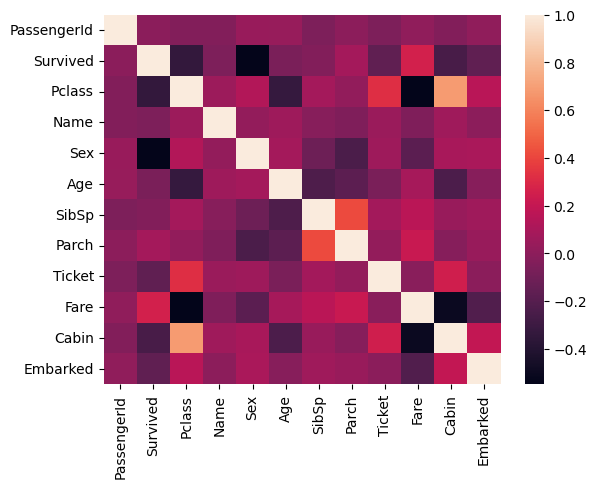

In [62]:
import seaborn as sns
sns.heatmap(df1.corr())

In [63]:
df1.corr()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,1.000000,-0.005007,-0.035144,-0.038559,0.042939,0.033207,-0.057527,-0.001652,-0.056554,0.012658,-0.035077,0.013083
Survived,-0.005007,1.000000,-0.338481,-0.057343,-0.543351,-0.069809,-0.035322,0.081629,-0.164549,0.257307,-0.254888,-0.163517
Pclass,-0.035144,-0.338481,1.000000,0.052831,0.131900,-0.331339,0.083081,0.018443,0.319869,-0.549500,0.684121,0.157112
Name,-0.038559,-0.057343,0.052831,1.000000,0.020314,0.057466,-0.017230,-0.049105,0.047348,-0.049173,0.061959,-0.004557
Sex,0.042939,-0.543351,0.131900,0.020314,1.000000,0.084153,-0.114631,-0.245489,0.059372,-0.182333,0.096681,0.104057
Age,0.033207,-0.069809,-0.331339,0.057466,0.084153,1.000000,-0.232625,-0.179191,-0.068848,0.091566,-0.235406,-0.022239
SibSp,-0.057527,-0.035322,0.083081,-0.017230,-0.114631,-0.232625,1.000000,0.414838,0.079461,0.159651,0.043593,0.066654
Parch,-0.001652,0.081629,0.018443,-0.049105,-0.245489,-0.179191,0.414838,1.000000,0.020003,0.216225,-0.028324,0.038322
Ticket,-0.056554,-0.164549,0.319869,0.047348,0.059372,-0.068848,0.079461,0.020003,1.000000,-0.013885,0.243696,-0.006041
Fare,0.012658,0.257307,-0.549500,-0.049173,-0.182333,0.091566,0.159651,0.216225,-0.013885,1.000000,-0.503355,-0.221226


In [64]:
x201=df1.drop(['Survived','PassengerId','Survived','Pclass','Name','Sex','Ticket','Cabin','Embarked'],axis=1)
y201=df1['Survived']

In [65]:
x201.head()

,Age,SibSp,Parch,Fare
0,22.0,1,0,7.2500
1,38.0,1,0,71.2833
2,26.0,0,0,7.9250
3,35.0,1,0,53.1000
4,35.0,0,0,8.0500


In [66]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
sc201=MinMaxScaler()
x_std201=sc1.fit_transform(x201)
x_std201

array([[0.27117366, 0.125     , 0.        , 0.01415106],
       [0.4722292 , 0.125     , 0.        , 0.13913574],
       [0.32143755, 0.        , 0.        , 0.01546857],
       ...,
       [0.36792055, 0.125     , 0.33333333, 0.04577135],
       [0.32143755, 0.        , 0.        , 0.0585561 ],
       [0.39683338, 0.        , 0.        , 0.01512699]])

In [67]:
x211=pd.DataFrame(x_std201)
x211.columns=x201.columns

In [68]:
x201

,Age,SibSp,Parch,Fare
0,22.000000,1,0,7.2500
1,38.000000,1,0,71.2833
2,26.000000,0,0,7.9250
3,35.000000,1,0,53.1000
4,35.000000,0,0,8.0500
...,...,...,...,...
886,27.000000,0,0,13.0000
887,19.000000,0,0,30.0000
888,29.699118,1,2,23.4500
889,26.000000,0,0,30.0000


In [69]:
x11=df1[['PassengerId','Pclass','Name','Sex','Ticket','Cabin','Embarked']]

In [70]:
x11.head()

,PassengerId,Pclass,Name,Sex,Ticket,Cabin,Embarked
0,1,3,108,1,523,147,2
1,2,1,190,0,596,81,0
2,3,3,353,0,669,147,2
3,4,1,272,0,49,55,2
4,5,3,15,1,472,147,2


In [71]:
combine= pd.concat([x11,x201], axis=1)
combine

,PassengerId,Pclass,Name,Sex,Ticket,Cabin,Embarked,Age,SibSp,Parch,Fare
0,1,3,108,1,523,147,2,22.000000,1,0,7.2500
1,2,1,190,0,596,81,0,38.000000,1,0,71.2833
2,3,3,353,0,669,147,2,26.000000,0,0,7.9250
3,4,1,272,0,49,55,2,35.000000,1,0,53.1000
4,5,3,15,1,472,147,2,35.000000,0,0,8.0500
...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,548,1,101,147,2,27.000000,0,0,13.0000
887,888,1,303,0,14,30,2,19.000000,0,0,30.0000
888,889,3,413,0,675,147,2,29.699118,1,2,23.4500
889,890,1,81,1,8,60,0,26.000000,0,0,30.0000


In [72]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(combine,y201,train_size=0.8,random_state=123456)

In [73]:
from sklearn.linear_model import LogisticRegressionCV
model201=LogisticRegressionCV()
model201.fit(x_train,y_train)

LogisticRegressionCV()

In [74]:
from sklearn.neighbors import KNeighborsClassifier
model202=KNeighborsClassifier(n_neighbors=9)


In [75]:
model202.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=9)

In [76]:
from sklearn.svm import SVC
model203= SVC(C=2,kernel='rbf')

In [77]:
model203.fit(x_train,y_train)

SVC(C=2)

In [78]:
from sklearn.tree import DecisionTreeClassifier
model204=DecisionTreeClassifier()
model204.fit(x_train,y_train)

DecisionTreeClassifier()

In [79]:
from sklearn.ensemble import RandomForestClassifier

model205= RandomForestClassifier()

model205.fit(x_train,y_train)

RandomForestClassifier()

In [80]:
from sklearn.ensemble import AdaBoostClassifier
model206 = AdaBoostClassifier()
model206.fit(x_train, y_train)


AdaBoostClassifier()

In [81]:
from catboost import CatBoostClassifier
model207 = CatBoostClassifier(logging_level='Silent')
model207.fit(x_train, y_train)


In [82]:
model201.predict([[1,3,108,1,22.0,1,0,523,7.2500,147,2]])

array([0])

In [83]:
model202.predict([[1,3,108,1,22.0,1,0,523,7.2500,147,2]])

array([0])

In [84]:
model203.predict([[1,3,108,1,22.0,1,0,523,7.2500,147,2]])

array([0])

In [85]:
model204.predict([[1,3,108,1,22.0,1,0,523,7.2500,147,2]])

array([0])

In [95]:
model205.predict([[1,3,108,1,22.0,1,0,523,7.2500,147,2]])

array([0])

In [86]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred201 = model201.predict(x_test)
y_true201 = y_test

accuracy201 = accuracy_score(y_true201, y_pred201)
precision201 = precision_score(y_true201, y_pred201, average='macro')
recall201 = recall_score(y_true201, y_pred201, average='macro')
f1201 = f1_score(y_true201, y_pred201, average='macro')

print(f"accuracy = {accuracy201:.2f}")
print(f"precision = {precision201:.2f}")
print(f"recall = {recall201:.2f}")
print(f"f1 = {f1201:.2f}")

accuracy = 0.78
precision = 0.77
recall = 0.77
f1 = 0.77


In [87]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred202 = model202.predict(x_test)
y_true202 = y_test

accuracy202 = accuracy_score(y_true202, y_pred202)
precision202 = precision_score(y_true202, y_pred202, average='macro')
recall202 = recall_score(y_true202, y_pred202, average='macro')
f1202= f1_score(y_true202, y_pred202, average='macro')

print(f"accuracy = {accuracy202:.2f}")
print(f"precision = {precision202:.2f}")
print(f"recall = {recall202:.2f}")
print(f"f1 = {f1202:.2f}")

accuracy = 0.63
precision = 0.60
recall = 0.58
f1 = 0.57


In [88]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred203 = model203.predict(x_test)
y_true203 = y_test

accuracy203= accuracy_score(y_true203, y_pred203)
precision203 = precision_score(y_true203, y_pred203, average='macro')
recall203 = recall_score(y_true203, y_pred203, average='macro')
f1203= f1_score(y_true203, y_pred203, average='macro')

print(f"accuracy = {accuracy203:.2f}")
print(f"precision = {precision203:.2f}")
print(f"recall = {recall203:.2f}")
print(f"f1 = {f1203:.2f}")

accuracy = 0.66
precision = 0.66
recall = 0.59
f1 = 0.58


In [89]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred204 = model204.predict(x_test)
y_true204 = y_test

accuracy204= accuracy_score(y_true204, y_pred204)
precision204 = precision_score(y_true204, y_pred204, average='macro')
recall204 = recall_score(y_true204, y_pred204, average='macro')
f1204= f1_score(y_true204, y_pred204, average='macro')

print(f"accuracy = {accuracy204:.2f}")
print(f"precision = {precision204:.2f}")
print(f"recall = {recall204:.2f}")
print(f"f1 = {f1204:.2f}")

accuracy = 0.78
precision = 0.77
recall = 0.77
f1 = 0.77


In [90]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred205 = model205.predict(x_test)
y_true205 = y_test

accuracy205= accuracy_score(y_true205, y_pred205)
precision205 = precision_score(y_true205, y_pred205, average='macro')
recall205 = recall_score(y_true205, y_pred205, average='macro')
f1205= f1_score(y_true205, y_pred205, average='macro')

print(f"accuracy = {accuracy205:.2f}")
print(f"precision = {precision205:.2f}")
print(f"recall = {recall205:.2f}")
print(f"f1 = {f1205:.2f}")

accuracy = 0.82
precision = 0.81
recall = 0.80
f1 = 0.81


In [91]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred206 = model206.predict(x_test)
y_true206 = y_test

accuracy206= accuracy_score(y_true206, y_pred206)
precision206 = precision_score(y_true206, y_pred206, average='macro')
recall206 = recall_score(y_true206, y_pred206, average='macro')
f1206= f1_score(y_true206, y_pred206, average='macro')

print(f"accuracy = {accuracy206:.2f}")
print(f"precision = {precision206:.2f}")
print(f"recall = {recall206:.2f}")
print(f"f1 = {f1206:.2f}")

accuracy = 0.77
precision = 0.76
recall = 0.75
f1 = 0.75


In [92]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred207 = model207.predict(x_test)
y_true207 = y_test

accuracy207= accuracy_score(y_true207, y_pred207)
precision207 = precision_score(y_true207, y_pred207, average='macro')
recall207 = recall_score(y_true207, y_pred207, average='macro')
f1207= f1_score(y_true207, y_pred207, average='macro')

print(f"accuracy = {accuracy207:.2f}")
print(f"precision = {precision207:.2f}")
print(f"recall = {recall207:.2f}")
print(f"f1 = {f1207:.2f}")

accuracy = 0.80
precision = 0.79
recall = 0.79
f1 = 0.79


#Que.3
The diabetes.csv dataset contains medical diagnostic measurements of patients. The goal is to analyze these health parameters and predict whether a patient is diabetic or not.
Each record in the dataset represents a patient with the following attributes:
Pregnancies
Glucose
BloodPressure
SkinThickness
Insulin
BMI
DiabetesPedigreeFunction
Age
Outcome (0 = Non-Diabetic, 1 = Diabetic)
Prepare model by using Logistic Regression, KNN, SVM, Decision Tree, Random Forest, AdaBoost, CatBoost & Calculate Accuracy by confusion matrix, Calculate accuracy score, precision score, recall score, f1 score.
Also Prepare summary of all models & Select best of them.

In [93]:
df2=pd.read_csv(r"C:\Users\SUMEDH\Desktop\New folder\IIT-08-A-DS\Datasets\diabetes.csv")
df2

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [94]:
df2.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [95]:
df2.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [96]:
df2.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [97]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [98]:
print(df2.isna().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [99]:
x202=df2.drop(['Outcome'],axis=1)
y202=df2['Outcome']

In [100]:
x202

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [101]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
sc202=MinMaxScaler()
x_std202=sc1.fit_transform(x202)
x_std202

array([[0.35294118, 0.74371859, 0.59016393, ..., 0.50074516, 0.23441503,
        0.48333333],
       [0.05882353, 0.42713568, 0.54098361, ..., 0.39642325, 0.11656704,
        0.16666667],
       [0.47058824, 0.91959799, 0.52459016, ..., 0.34724292, 0.25362938,
        0.18333333],
       ...,
       [0.29411765, 0.6080402 , 0.59016393, ..., 0.390462  , 0.07130658,
        0.15      ],
       [0.05882353, 0.63316583, 0.49180328, ..., 0.4485842 , 0.11571307,
        0.43333333],
       [0.05882353, 0.46733668, 0.57377049, ..., 0.45305514, 0.10119556,
        0.03333333]])

In [102]:
x212=pd.DataFrame(x_std202)
x212.columns=x202.columns


In [103]:
x202

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [104]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x202,y202,train_size=0.8,random_state=123456)

In [105]:
from sklearn.linear_model import LogisticRegressionCV
model301=LogisticRegressionCV()
model301.fit(x_train,y_train)

LogisticRegressionCV()

In [106]:
from sklearn.neighbors import KNeighborsClassifier
model302=KNeighborsClassifier(n_neighbors=9)


In [107]:
model302.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=9)

In [108]:
from sklearn.svm import SVC
model303= SVC(C=2,kernel='rbf')

In [109]:
model303.fit(x_train,y_train)


SVC(C=2)

In [110]:
from sklearn.tree import DecisionTreeClassifier
model304=DecisionTreeClassifier()
model304.fit(x_train,y_train)

DecisionTreeClassifier()

In [111]:
from sklearn.ensemble import RandomForestClassifier

model305= RandomForestClassifier()

model305.fit(x_train,y_train)

RandomForestClassifier()

In [112]:
from sklearn.ensemble import AdaBoostClassifier
model306 = AdaBoostClassifier()
model306.fit(x_train, y_train)


AdaBoostClassifier()

In [113]:
from catboost import CatBoostClassifier
model307 = CatBoostClassifier(logging_level='Silent')
model307.fit(x_train, y_train)


In [114]:
model301.predict([[6,148,72,35,0,33.6,0.627,50]])

array([1])

In [115]:
model302.predict([[6,148,72,35,0,33.6,0.627,50]])

array([1])

In [116]:
model303.predict([[6,148,72,35,0,33.6,0.627,50]])

array([0])

In [117]:
model304.predict([[6,148,72,35,0,33.6,0.627,50]])

array([1])

In [118]:
model305.predict([[6,148,72,35,0,33.6,0.627,50]])

array([1])

In [119]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred301 = model301.predict(x_test)
y_true301 = y_test

accuracy301 = accuracy_score(y_true301, y_pred301)
precision301 = precision_score(y_true301, y_pred301, average='macro')
recall301 = recall_score(y_true301, y_pred301, average='macro')
f1301 = f1_score(y_true301, y_pred301, average='macro')

print(f"accuracy = {accuracy301:.2f}")
print(f"precision = {precision301:.2f}")
print(f"recall = {recall301:.2f}")
print(f"f1 = {f1301:.2f}")

accuracy = 0.75
precision = 0.75
recall = 0.73
f1 = 0.73


In [120]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred302 = model302.predict(x_test)
y_true302 = y_test

accuracy302 = accuracy_score(y_true302, y_pred302)
precision302 = precision_score(y_true302, y_pred302, average='macro')
recall302 = recall_score(y_true302, y_pred302, average='macro')
f1302= f1_score(y_true302, y_pred302, average='macro')

print(f"accuracy = {accuracy302:.2f}")
print(f"precision = {precision302:.2f}")
print(f"recall = {recall302:.2f}")
print(f"f1 = {f1302:.2f}")

accuracy = 0.73
precision = 0.73
recall = 0.71
f1 = 0.71


In [121]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred303 = model303.predict(x_test)
y_true303 = y_test

accuracy303= accuracy_score(y_true303, y_pred303)
precision303 = precision_score(y_true303, y_pred303, average='macro')
recall303 = recall_score(y_true303, y_pred303, average='macro')
f1303= f1_score(y_true303, y_pred303, average='macro')

print(f"accuracy = {accuracy303:.2f}")
print(f"precision = {precision303:.2f}")
print(f"recall = {recall303:.2f}")
print(f"f1 = {f1303:.2f}")

accuracy = 0.73
precision = 0.76
recall = 0.71
f1 = 0.71


In [122]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred304 = model304.predict(x_test)
y_true304 = y_test

accuracy304= accuracy_score(y_true304, y_pred304)
precision304 = precision_score(y_true304, y_pred304, average='macro')
recall304 = recall_score(y_true304, y_pred304, average='macro')
f1304= f1_score(y_true304, y_pred304, average='macro')

print(f"accuracy = {accuracy304:.2f}")
print(f"precision = {precision304:.2f}")
print(f"recall = {recall304:.2f}")
print(f"f1 = {f1304:.2f}")

accuracy = 0.71
precision = 0.71
recall = 0.69
f1 = 0.69


In [123]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred305 = model305.predict(x_test)
y_true305 = y_test

accuracy305= accuracy_score(y_true305, y_pred305)
precision305 = precision_score(y_true305, y_pred305, average='macro')
recall305 = recall_score(y_true305, y_pred305, average='macro')
f1305= f1_score(y_true305, y_pred305, average='macro')

print(f"accuracy = {accuracy305:.2f}")
print(f"precision = {precision305:.2f}")
print(f"recall = {recall305:.2f}")
print(f"f1 = {f1305:.2f}")

accuracy = 0.74
precision = 0.74
recall = 0.73
f1 = 0.73


In [124]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred306 = model306.predict(x_test)
y_true306 = y_test

accuracy306= accuracy_score(y_true306, y_pred306)
precision306 = precision_score(y_true306, y_pred306, average='macro')
recall306 = recall_score(y_true306, y_pred306, average='macro')
f1306= f1_score(y_true306, y_pred306, average='macro')

print(f"accuracy = {accuracy306:.2f}")
print(f"precision = {precision306:.2f}")
print(f"recall = {recall306:.2f}")
print(f"f1 = {f1306:.2f}")

accuracy = 0.73
precision = 0.73
recall = 0.72
f1 = 0.72


In [125]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred307 = model307.predict(x_test)
y_true307 = y_test

accuracy307= accuracy_score(y_true307, y_pred307)
precision307 = precision_score(y_true307, y_pred307, average='macro')
recall307 = recall_score(y_true307, y_pred307, average='macro')
f1307= f1_score(y_true307, y_pred307, average='macro')

print(f"accuracy = {accuracy307:.2f}")
print(f"precision = {precision307:.2f}")
print(f"recall = {recall307:.2f}")
print(f"f1 = {f1307:.2f}")

accuracy = 0.76
precision = 0.76
recall = 0.75
f1 = 0.75


#Que.4
The ObesityLevel.csv dataset contains information related to individuals’ eating habits, physical condition, and lifestyle factors. 
The dataset is used to estimate obesity levels in individuals from Mexico, Peru, and Colombia.

Dataset Description:
Each record represents an individual with multiple attributes, including:
Physical Characteristics
Age
Height
Weight

Eating Habits
Frequent consumption of high caloric food (FAVC)
Frequency of consumption of vegetables (FCVC)
Number of main meals (NCP)
Consumption of food between meals (CAEC)
Consumption of alcohol (CALC)

Physical Activity & Lifestyle
Physical activity frequency (FAF)
Time using technology devices (TUE)
Transportation used (MTRANS)

Other Attributes
Gender
Family history with overweight (family_history_with_overweight)
Smoking habits (SMOKE)
Water consumption daily (CH2O)

Target Variable
NObesity (Obesity Level)

Build Logistic Regression, KNN, SVM, Decision Tree, Random Forest, AdaBoost, CatBoost models that can predict the obesity level of an individual based on their physical attributes and lifestyle habits.
Calculate Accuracy by confusion matrix, Calculate accuracy score, precision score, recall score, f1 score.
Also Prepare summary of all models & Select best of them.

In [126]:
df3=pd.read_csv(r"C:\Users\SUMEDH\Desktop\New folder\IIT-08-A-DS\Datasets\ObesityLevel.csv")
df3

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.000000,Female,1.620000,64.000000,no,no,2.0,3.0,no,no,2.000000,yes,0.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
1,21.000000,Female,1.520000,56.000000,Sometimes,no,3.0,3.0,yes,yes,3.000000,yes,3.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
2,23.000000,Male,1.800000,77.000000,Frequently,no,2.0,3.0,no,no,2.000000,yes,2.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
3,27.000000,Male,1.800000,87.000000,Frequently,no,3.0,3.0,no,no,2.000000,no,2.000000,0.000000,Sometimes,Walking,Overweight_Level_I
4,22.000000,Male,1.780000,89.800000,Sometimes,no,2.0,1.0,no,no,2.000000,no,0.000000,0.000000,Sometimes,Public_Transportation,Overweight_Level_II
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,20.976842,Female,1.710730,131.408528,Sometimes,yes,3.0,3.0,no,no,1.728139,yes,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,21.982942,Female,1.748584,133.742943,Sometimes,yes,3.0,3.0,no,no,2.005130,yes,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,22.524036,Female,1.752206,133.689352,Sometimes,yes,3.0,3.0,no,no,2.054193,yes,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,24.361936,Female,1.739450,133.346641,Sometimes,yes,3.0,3.0,no,no,2.852339,yes,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III


In [127]:
df3.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [128]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   object 
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   object 
 12  FAF                             21

In [129]:
df3['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [130]:
df3['CALC'].unique()

array(['no', 'Sometimes', 'Frequently', 'Always'], dtype=object)

In [131]:
df3['FAVC'].unique()

array(['no', 'yes'], dtype=object)

In [132]:
df3['SCC'].unique()

array(['no', 'yes'], dtype=object)

In [133]:
df3['SMOKE'].unique()


array(['no', 'yes'], dtype=object)

In [134]:
df3['family_history_with_overweight'].unique()



array(['yes', 'no'], dtype=object)

In [135]:
df3['CAEC'].unique()


array(['Sometimes', 'Frequently', 'Always', 'no'], dtype=object)

In [136]:
df3['MTRANS'].unique()

array(['Public_Transportation', 'Walking', 'Automobile', 'Motorbike',
       'Bike'], dtype=object)

In [137]:
df3['NObeyesdad'].unique()

array(['Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
       'Obesity_Type_I', 'Insufficient_Weight', 'Obesity_Type_II',
       'Obesity_Type_III'], dtype=object)

In [138]:
from sklearn.preprocessing import LabelEncoder
df3['Gender']=LabelEncoder().fit_transform(df3['Gender'])
df3['CALC']=LabelEncoder().fit_transform(df3['CALC'])
df3['FAVC']=LabelEncoder().fit_transform(df3['FAVC'])
df3['SCC']=LabelEncoder().fit_transform(df3['SCC'])
df3['SMOKE']=LabelEncoder().fit_transform(df3['SMOKE'])
df3['family_history_with_overweight']=LabelEncoder().fit_transform(df3['family_history_with_overweight'])
df3['CAEC']=LabelEncoder().fit_transform(df3['CAEC'])
df3['MTRANS']=LabelEncoder().fit_transform(df3['MTRANS'])
df3['NObeyesdad']=LabelEncoder().fit_transform(df3['NObeyesdad'])




In [139]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   int64  
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   int64  
 5   FAVC                            2111 non-null   int64  
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   int64  
 9   SMOKE                           2111 non-null   int64  
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   int64  
 12  FAF                             21

In [140]:
print(df3.isna().sum())

Age                               0
Gender                            0
Height                            0
Weight                            0
CALC                              0
FAVC                              0
FCVC                              0
NCP                               0
SCC                               0
SMOKE                             0
CH2O                              0
family_history_with_overweight    0
FAF                               0
TUE                               0
CAEC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64


In [141]:
df3.corr()

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
Age,1.000000,0.048394,-0.025958,0.202560,-0.044487,0.063902,0.016291,-0.043944,-0.116283,0.091987,-0.045304,0.205725,-0.144938,-0.296931,0.083739,-0.601945,0.236170
Gender,0.048394,1.000000,0.618466,0.161668,0.007616,0.064934,-0.274505,0.067600,-0.102633,0.044698,0.107930,0.102512,0.189607,0.017269,0.091543,-0.137537,0.024908
Height,-0.025958,0.618466,1.000000,0.463136,-0.129732,0.178364,-0.038121,0.243672,-0.133753,0.055499,0.213376,0.247684,0.294709,0.051912,0.048818,-0.073609,0.038986
Weight,0.202560,0.161668,0.463136,1.000000,-0.206677,0.272300,0.216125,0.107469,-0.201906,0.025746,0.200575,0.496820,-0.051436,-0.071561,0.287493,0.004610,0.387643
CALC,-0.044487,0.007616,-0.129732,-0.206677,1.000000,-0.089520,-0.060781,-0.071747,-0.003463,-0.082471,-0.091386,0.036676,0.086799,0.045864,-0.047540,-0.012452,-0.134632
FAVC,0.063902,0.064934,0.178364,0.272300,-0.089520,1.000000,-0.027283,-0.007000,-0.190658,-0.050660,0.009719,0.208036,-0.107995,0.068417,0.150068,-0.069800,0.044582
FCVC,0.016291,-0.274505,-0.038121,0.216125,-0.060781,-0.027283,1.000000,0.042216,0.071852,0.014320,0.068461,0.040372,0.019939,-0.101135,-0.054670,0.064743,0.018522
NCP,-0.043944,0.067600,0.243672,0.107469,-0.071747,-0.007000,0.042216,1.000000,-0.015624,0.007811,0.057088,0.071370,0.129504,0.036326,-0.097801,-0.053858,-0.092616
SCC,-0.116283,-0.102633,-0.133753,-0.201906,-0.003463,-0.190658,0.071852,-0.015624,1.000000,0.047731,0.008036,-0.185422,0.074221,-0.010928,-0.109179,0.043157,-0.050679
SMOKE,0.091987,0.044698,0.055499,0.025746,-0.082471,-0.050660,0.014320,0.007811,0.047731,1.000000,-0.031995,0.017385,0.011216,0.017613,-0.055282,-0.010702,-0.023256


In [142]:
x203=df3.drop(['Gender','CALC','FAVC','SCC','SMOKE','family_history_with_overweight','CAEC','MTRANS','NObeyesdad'],axis=1)
y203=df3['NObeyesdad']

In [143]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
sc203=MinMaxScaler()
x_std203=sc1.fit_transform(x203)
x_std203

array([[0.14893617, 0.32075472, 0.18656716, ..., 0.5       , 0.        ,
        0.5       ],
       [0.14893617, 0.13207547, 0.12686567, ..., 1.        , 1.        ,
        0.        ],
       [0.19148936, 0.66037736, 0.28358209, ..., 0.5       , 0.66666667,
        0.5       ],
       ...,
       [0.18136247, 0.5702    , 0.70663696, ..., 0.5270965 , 0.471403  ,
        0.323144  ],
       [0.22046672, 0.54613208, 0.70407941, ..., 0.9261695 , 0.37970233,
        0.2930175 ],
       [0.20563211, 0.54497358, 0.70501971, ..., 0.9317565 , 0.34215067,
        0.3570685 ]])

In [144]:
x213=pd.DataFrame(x_std203)
x213.columns=x203.columns

In [145]:
x203

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
0,21.000000,1.620000,64.000000,2.0,3.0,2.000000,0.000000,1.000000
1,21.000000,1.520000,56.000000,3.0,3.0,3.000000,3.000000,0.000000
2,23.000000,1.800000,77.000000,2.0,3.0,2.000000,2.000000,1.000000
3,27.000000,1.800000,87.000000,3.0,3.0,2.000000,2.000000,0.000000
4,22.000000,1.780000,89.800000,2.0,1.0,2.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...
2106,20.976842,1.710730,131.408528,3.0,3.0,1.728139,1.676269,0.906247
2107,21.982942,1.748584,133.742943,3.0,3.0,2.005130,1.341390,0.599270
2108,22.524036,1.752206,133.689352,3.0,3.0,2.054193,1.414209,0.646288
2109,24.361936,1.739450,133.346641,3.0,3.0,2.852339,1.139107,0.586035


In [146]:
x12=df3[['Gender','CALC','FAVC','SCC','SMOKE','family_history_with_overweight','CAEC','MTRANS']]

In [147]:
combine1= pd.concat([x12,x203], axis=1)
combine1

,Gender,CALC,FAVC,SCC,SMOKE,family_history_with_overweight,CAEC,MTRANS,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
0,0,3,0,0,0,1,2,3,21.000000,1.620000,64.000000,2.0,3.0,2.000000,0.000000,1.000000
1,0,2,0,1,1,1,2,3,21.000000,1.520000,56.000000,3.0,3.0,3.000000,3.000000,0.000000
2,1,1,0,0,0,1,2,3,23.000000,1.800000,77.000000,2.0,3.0,2.000000,2.000000,1.000000
3,1,1,0,0,0,0,2,4,27.000000,1.800000,87.000000,3.0,3.0,2.000000,2.000000,0.000000
4,1,2,0,0,0,0,2,3,22.000000,1.780000,89.800000,2.0,1.0,2.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,0,2,1,0,0,1,2,3,20.976842,1.710730,131.408528,3.0,3.0,1.728139,1.676269,0.906247
2107,0,2,1,0,0,1,2,3,21.982942,1.748584,133.742943,3.0,3.0,2.005130,1.341390,0.599270
2108,0,2,1,0,0,1,2,3,22.524036,1.752206,133.689352,3.0,3.0,2.054193,1.414209,0.646288
2109,0,2,1,0,0,1,2,3,24.361936,1.739450,133.346641,3.0,3.0,2.852339,1.139107,0.586035


In [148]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(combine1,y203,train_size=0.8,random_state=123456)

In [149]:
from sklearn.linear_model import LogisticRegressionCV
model401=LogisticRegressionCV()
model401.fit(x_train,y_train)

LogisticRegressionCV()

In [150]:
from sklearn.neighbors import KNeighborsClassifier
model402=KNeighborsClassifier(n_neighbors=9)

In [151]:
model402.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=9)

In [152]:
from sklearn.svm import SVC
model403= SVC(C=2,kernel='rbf')

In [153]:
model403.fit(x_train,y_train)

SVC(C=2)

In [154]:
from sklearn.tree import DecisionTreeClassifier
model404=DecisionTreeClassifier()
model404.fit(x_train,y_train)

DecisionTreeClassifier()

In [155]:
from sklearn.ensemble import RandomForestClassifier

model405= RandomForestClassifier()

model405.fit(x_train,y_train)

RandomForestClassifier()

In [156]:
from sklearn.ensemble import AdaBoostClassifier
model406 = AdaBoostClassifier()
model406.fit(x_train, y_train)

AdaBoostClassifier()

In [157]:
from catboost import CatBoostClassifier
model407 = CatBoostClassifier(logging_level='Silent')
model407.fit(x_train, y_train)


In [158]:
model401.predict([[0,3,0,0,0,1,2,3,21.000000,1.620000,64.000000,2.0,3.0,2.000000,0.000000,1.000000]])

array([6])

In [159]:
model402.predict([[0,3,0,0,0,1,2,3,21.000000,1.620000,64.000000,2.0,3.0,2.000000,0.000000,1.000000]])

array([1])

In [160]:
model403.predict([[0,3,0,0,0,1,2,3,21.000000,1.620000,64.000000,2.0,3.0,2.000000,0.000000,1.000000]])

array([1])

In [161]:
model404.predict([[0,3,0,0,0,1,2,3,21.000000,1.620000,64.000000,2.0,3.0,2.000000,0.000000,1.000000]])

array([1])

In [162]:
model405.predict([[0,3,0,0,0,1,2,3,21.000000,1.620000,64.000000,2.0,3.0,2.000000,0.000000,1.000000]])

array([1])

In [163]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred401 = model401.predict(x_test)
y_true401 = y_test

accuracy401 = accuracy_score(y_true401, y_pred401)
precision401 = precision_score(y_true401, y_pred401, average='macro')
recall401 = recall_score(y_true401, y_pred401, average='macro')
f1401 = f1_score(y_true401, y_pred401, average='macro')

print(f"accuracy = {accuracy401:.2f}")
print(f"precision = {precision401:.2f}")
print(f"recall = {recall401:.2f}")
print(f"f1 = {f1401:.2f}")

accuracy = 0.79
precision = 0.76
recall = 0.77
f1 = 0.76


In [164]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred402 = model402.predict(x_test)
y_true402 = y_test

accuracy402 = accuracy_score(y_true402, y_pred402)
precision402 = precision_score(y_true402, y_pred402, average='macro')
recall402 = recall_score(y_true402, y_pred402, average='macro')
f1402 = f1_score(y_true402, y_pred402, average='macro')

print(f"accuracy = {accuracy402:.2f}")
print(f"precision = {precision402:.2f}")
print(f"recall = {recall402:.2f}")
print(f"f1 = {f1402:.2f}")

accuracy = 0.85
precision = 0.83
recall = 0.83
f1 = 0.83


In [165]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred403 = model403.predict(x_test)
y_true403 = y_test

accuracy403 = accuracy_score(y_true403, y_pred403)
precision403 = precision_score(y_true403, y_pred403, average='macro')
recall403 = recall_score(y_true403, y_pred403, average='macro')
f1403 = f1_score(y_true403, y_pred403, average='macro')

print(f"accuracy = {accuracy403:.2f}")
print(f"precision = {precision403:.2f}")
print(f"recall = {recall403:.2f}")
print(f"f1 = {f1403:.2f}")

accuracy = 0.62
precision = 0.63
recall = 0.62
f1 = 0.60


In [166]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred404 = model404.predict(x_test)
y_true404 = y_test

accuracy404 = accuracy_score(y_true404, y_pred404)
precision404 = precision_score(y_true404, y_pred404, average='macro')
recall404 = recall_score(y_true404, y_pred404, average='macro')
f1404 = f1_score(y_true404, y_pred404, average='macro')

print(f"accuracy = {accuracy404:.2f}")
print(f"precision = {precision404:.2f}")
print(f"recall = {recall404:.2f}")
print(f"f1 = {f1404:.2f}")

accuracy = 0.93
precision = 0.93
recall = 0.93
f1 = 0.93


In [167]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred405 = model405.predict(x_test)
y_true405 = y_test

accuracy405 = accuracy_score(y_true405, y_pred405)
precision405 = precision_score(y_true405, y_pred405, average='macro')
recall405 = recall_score(y_true405, y_pred405, average='macro')
f1405 = f1_score(y_true405, y_pred405, average='macro')

print(f"accuracy = {accuracy405:.2f}")
print(f"precision = {precision405:.2f}")
print(f"recall = {recall405:.2f}")
print(f"f1 = {f1405:.2f}")

accuracy = 0.94
precision = 0.94
recall = 0.94
f1 = 0.94


In [168]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred406 = model406.predict(x_test)
y_true406 = y_test

accuracy406 = accuracy_score(y_true406, y_pred406)
precision406 = precision_score(y_true406, y_pred406, average='macro')
recall406 = recall_score(y_true406, y_pred406, average='macro')
f1406 = f1_score(y_true406, y_pred406, average='macro')

print(f"accuracy = {accuracy406:.2f}")
print(f"precision = {precision406:.2f}")
print(f"recall = {recall406:.2f}")
print(f"f1 = {f1406:.2f}")

accuracy = 0.44
precision = 0.26
recall = 0.41
f1 = 0.30


In [169]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred407 = model407.predict(x_test)
y_true407 = y_test

accuracy407 = accuracy_score(y_true407, y_pred407)
precision407 = precision_score(y_true407, y_pred407, average='macro')
recall407 = recall_score(y_true407, y_pred407, average='macro')
f1407 = f1_score(y_true407, y_pred407, average='macro')

print(f"accuracy = {accuracy407:.2f}")
print(f"precision = {precision407:.2f}")
print(f"recall = {recall407:.2f}")
print(f"f1 = {f1407:.2f}")

accuracy = 0.96
precision = 0.96
recall = 0.96
f1 = 0.96


#Que.5
The heart.csv dataset contains clinical and demographic information of patients. 
The objective is to analyze these medical attributes and predict whether a patient has heart disease.

Dataset Description:
Each record represents a patient with the following attributes:
Age
Sex
ChestPainType
RestingBP (Resting Blood Pressure)
Cholesterol
FastingBS (Fasting Blood Sugar)
RestingECG
MaxHR (Maximum Heart Rate Achieved)
ExerciseAngina
Oldpeak (ST depression)
ST_Slope
HeartDisease

Build Logistic Regression, KNN, SVM, Decision Tree, Random Forest, AdaBoost, CatBoost models that can predict the presence or absence of heart disease based on patient health indicators.
Calculate Accuracy by confusion matrix, Calculate accuracy score, precision score, recall score, f1 score.
Also Prepare summary of all models & Select best of them.

In [170]:
df4=pd.read_csv(r"C:\Users\SUMEDH\Desktop\New folder\IIT-08-A-DS\Datasets\heart.csv")
df4

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [171]:
df4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [172]:
print(df4.isna().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [173]:
x204=df4.drop(['sex','cp','fbs','restecg','exang','slope','ca','thal','target'],axis=1)
y204=df4['target']

In [174]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
sc204=MinMaxScaler()
x_std204=sc1.fit_transform(x204)
x_std204

array([[0.70833333, 0.48113208, 0.24429224, 0.60305344, 0.37096774],
       [0.16666667, 0.33962264, 0.28310502, 0.88549618, 0.56451613],
       [0.25      , 0.33962264, 0.17808219, 0.77099237, 0.22580645],
       ...,
       [0.8125    , 0.47169811, 0.15296804, 0.53435115, 0.5483871 ],
       [0.58333333, 0.33962264, 0.01141553, 0.33587786, 0.19354839],
       [0.58333333, 0.33962264, 0.25114155, 0.78625954, 0.        ]])

In [175]:
x214=pd.DataFrame(x_std204)
x214.columns=x204.columns

In [176]:
x204

,age,trestbps,chol,thalach,oldpeak
0,63,145,233,150,2.3
1,37,130,250,187,3.5
2,41,130,204,172,1.4
3,56,120,236,178,0.8
4,57,120,354,163,0.6
...,...,...,...,...,...
298,57,140,241,123,0.2
299,45,110,264,132,1.2
300,68,144,193,141,3.4
301,57,130,131,115,1.2


In [177]:
x13=df4[['sex','cp','fbs','restecg','exang','slope','ca','thal']]

In [178]:
combine2= pd.concat([x13,x204], axis=1)
combine2

,sex,cp,fbs,restecg,exang,slope,ca,thal,age,trestbps,chol,thalach,oldpeak
0,1,3,1,0,0,0,0,1,63,145,233,150,2.3
1,1,2,0,1,0,0,0,2,37,130,250,187,3.5
2,0,1,0,0,0,2,0,2,41,130,204,172,1.4
3,1,1,0,1,0,2,0,2,56,120,236,178,0.8
4,0,0,0,1,1,2,0,2,57,120,354,163,0.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,0,0,0,1,1,1,0,3,57,140,241,123,0.2
299,1,3,0,1,0,1,0,3,45,110,264,132,1.2
300,1,0,1,1,0,1,2,3,68,144,193,141,3.4
301,1,0,0,1,1,1,1,3,57,130,131,115,1.2


In [179]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(combine2,y204,train_size=0.8,random_state=123456)

In [180]:
from sklearn.linear_model import LogisticRegressionCV
model501=LogisticRegressionCV()
model501.fit(x_train,y_train)

LogisticRegressionCV()

In [181]:
from sklearn.neighbors import KNeighborsClassifier
model502=KNeighborsClassifier(n_neighbors=9)

In [182]:
model502.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=9)

In [183]:
from sklearn.svm import SVC
model503= SVC(C=2,kernel='rbf')

In [184]:
model503.fit(x_train,y_train)

SVC(C=2)

In [185]:
from sklearn.tree import DecisionTreeClassifier
model504=DecisionTreeClassifier()
model504.fit(x_train,y_train)

DecisionTreeClassifier()

In [186]:
from sklearn.ensemble import RandomForestClassifier

model505= RandomForestClassifier()

model505.fit(x_train,y_train)

RandomForestClassifier()

In [187]:
from sklearn.ensemble import AdaBoostClassifier
model506 = AdaBoostClassifier()
model506.fit(x_train, y_train)

AdaBoostClassifier()

In [188]:
from catboost import CatBoostClassifier
model507 = CatBoostClassifier(logging_level='Silent')
model507.fit(x_train, y_train)

In [189]:
model501.predict([[1,3,1,0,0,0,0,1,63,145,233,150,2.3]])

array([1])

In [190]:
model502.predict([[1,3,1,0,0,0,0,1,63,145,233,150,2.3]])

array([1])

In [191]:
model503.predict([[1,3,1,0,0,0,0,1,63,145,233,150,2.3]])

array([1])

In [192]:
model504.predict([[1,3,1,0,0,0,0,1,63,145,233,150,2.3]])

array([1])

In [193]:
model505.predict([[1,3,1,0,0,0,0,1,63,145,233,150,2.3]])

array([1])

In [194]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred501 = model501.predict(x_test)
y_true501 = y_test

accuracy501 = accuracy_score(y_true501, y_pred501)
precision501 = precision_score(y_true501, y_pred501, average='macro')
recall501 = recall_score(y_true501, y_pred501, average='macro')
f1501 = f1_score(y_true501, y_pred501, average='macro')

print(f"accuracy = {accuracy501:.2f}")
print(f"precision = {precision501:.2f}")
print(f"recall = {recall501:.2f}")
print(f"f1 = {f1501:.2f}")

accuracy = 0.85
precision = 0.85
recall = 0.83
f1 = 0.84


In [195]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred502 = model502.predict(x_test)
y_true502 = y_test

accuracy502 = accuracy_score(y_true502, y_pred502)
precision502 = precision_score(y_true502, y_pred502, average='macro')
recall502 = recall_score(y_true502, y_pred502, average='macro')
f1502 = f1_score(y_true502, y_pred502, average='macro')

print(f"accuracy = {accuracy502:.2f}")
print(f"precision = {precision502:.2f}")
print(f"recall = {recall502:.2f}")
print(f"f1 = {f1502:.2f}")

accuracy = 0.62
precision = 0.60
recall = 0.60
f1 = 0.60


In [196]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred503 = model503.predict(x_test)
y_true503 = y_test

accuracy503 = accuracy_score(y_true503, y_pred503)
precision503 = precision_score(y_true503, y_pred503, average='macro')
recall503 = recall_score(y_true503, y_pred503, average='macro')
f1503 = f1_score(y_true503, y_pred503, average='macro')

print(f"accuracy = {accuracy503:.2f}")
print(f"precision = {precision503:.2f}")
print(f"recall = {recall503:.2f}")
print(f"f1 = {f1503:.2f}")

accuracy = 0.69
precision = 0.67
recall = 0.66
f1 = 0.66


In [197]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred504 = model504.predict(x_test)
y_true504 = y_test

accuracy504 = accuracy_score(y_true504, y_pred504)
precision504 = precision_score(y_true504, y_pred504, average='macro')
recall504 = recall_score(y_true504, y_pred504, average='macro')
f1504 = f1_score(y_true504, y_pred504, average='macro')

print(f"accuracy = {accuracy504:.2f}")
print(f"precision = {precision504:.2f}")
print(f"recall = {recall504:.2f}")
print(f"f1 = {f1504:.2f}")

accuracy = 0.66
precision = 0.65
recall = 0.66
f1 = 0.65


In [198]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred505 = model505.predict(x_test)
y_true505 = y_test

accuracy505 = accuracy_score(y_true505, y_pred505)
precision505 = precision_score(y_true505, y_pred505, average='macro')
recall505 = recall_score(y_true505, y_pred505, average='macro')
f1505 = f1_score(y_true505, y_pred502, average='macro')

print(f"accuracy = {accuracy502:.2f}")
print(f"precision = {precision502:.2f}")
print(f"recall = {recall502:.2f}")
print(f"f1 = {f1502:.2f}")

accuracy = 0.62
precision = 0.60
recall = 0.60
f1 = 0.60


In [199]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred506 = model506.predict(x_test)
y_true506 = y_test

accuracy506 = accuracy_score(y_true506, y_pred506)
precision506 = precision_score(y_true506, y_pred506, average='macro')
recall506 = recall_score(y_true506, y_pred506, average='macro')
f1506 = f1_score(y_true506, y_pred506, average='macro')

print(f"accuracy = {accuracy506:.2f}")
print(f"precision = {precision506:.2f}")
print(f"recall = {recall506:.2f}")
print(f"f1 = {f1506:.2f}")

accuracy = 0.77
precision = 0.76
recall = 0.77
f1 = 0.76


In [200]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred507 = model507.predict(x_test)
y_true507 = y_test

accuracy507 = accuracy_score(y_true507, y_pred507)
precision507 = precision_score(y_true507, y_pred507, average='macro')
recall507 = recall_score(y_true507, y_pred507, average='macro')
f1507 = f1_score(y_true507, y_pred507, average='macro')

print(f"accuracy = {accuracy506:.2f}")
print(f"precision = {precision506:.2f}")
print(f"recall = {recall506:.2f}")
print(f"f1 = {f1506:.2f}")

accuracy = 0.77
precision = 0.76
recall = 0.77
f1 = 0.76
